In [1]:
import os
os.environ['CUBLAS_WORKSPACE_CONFIG'] = ':4096:8'

import numpy as np
import matplotlib.pyplot as plt
import emcee
import corner
import os
import matplotlib.pyplot as plt

seed = 14
np.random.seed(seed)

# set matplotlib plotting style
plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.serif'] = ['cmr10']
plt.rcParams['mathtext.fontset'] ='cm'
plt.rcParams['figure.facecolor'] = 'white'
plt.rc('axes', unicode_minus=False)
plt.rc('axes.formatter', use_mathtext=True)

# set device for all tensors
device = 'cuda'

In [2]:
# load in the data
numerical_reader = emcee.backends.HDFBackend('mcmc_chains/cl_ee_IA_76walkers_100tau_CCL_chain.h5', read_only=True)
maml_reader = emcee.backends.HDFBackend('mcmc_chains/cl_ee_IA_76walkers_100tau_MAML_chain.h5', read_only=True)
pretrain_reader = emcee.backends.HDFBackend('mcmc_chains/cl_ee_IA_76walkers_100tau_pretrain_chain.h5', read_only=True)
fresh_reader = emcee.backends.HDFBackend('mcmc_chains/cl_ee_IA_76walkers_100tau_fresh_chain.h5', read_only=True)

In [3]:
# print length of chains
print("Numerical chain length:", numerical_reader.get_chain().shape)
print("MAML chain length:", maml_reader.get_chain().shape)
print("Pretrain chain length:", pretrain_reader.get_chain().shape)
print("Fresh chain length:", fresh_reader.get_chain().shape)

Numerical chain length: (9000, 76, 5)
MAML chain length: (10000, 76, 5)
Pretrain chain length: (10000, 76, 5)
Fresh chain length: (6000, 76, 5)


In [4]:
# Print max autocorr length
print('Numerical max autocorr length:', np.max(numerical_reader.get_autocorr_time()))
print('MAML max autocorr length:', np.max(maml_reader.get_autocorr_time()))
print('Pretrain max autocorr length:', np.max(pretrain_reader.get_autocorr_time()))
print('Fresh max autocorr length:', np.max(fresh_reader.get_autocorr_time()))

Numerical max autocorr length: 89.86473445682213
MAML max autocorr length: 97.41417450157049
Pretrain max autocorr length: 98.34250118228587
Fresh max autocorr length: 56.09335197057531


In [5]:
numerical_samples = numerical_reader.get_chain(discard=1000, flat=True)[:,:5]
maml_samples = maml_reader.get_chain(discard=1000, flat=True)[:,:5]
pretrain_samples = pretrain_reader.get_chain(discard=1000, flat=True)[:,:5]
fresh_samples = fresh_reader.get_chain(discard=1000, flat=True)[:,:5]

In [6]:
# Combine Omega_c and Omega_b to Omega_m
Omega_m = numerical_samples[:,0] + numerical_samples[:,1]
numerical_samples = np.concatenate((Omega_m[:,None], numerical_samples[:,2:]), axis=1)

Omega_m = maml_samples[:,0] + maml_samples[:,1]
maml_samples = np.concatenate((Omega_m[:,None], maml_samples[:,2:]), axis=1)

Omega_m = pretrain_samples[:,0] + pretrain_samples[:,1]
pretrain_samples = np.concatenate((Omega_m[:,None], pretrain_samples[:,2:]), axis=1)

Omega_m = fresh_samples[:,0] + fresh_samples[:,1]
fresh_samples = np.concatenate((Omega_m[:,None], fresh_samples[:,2:]), axis=1)

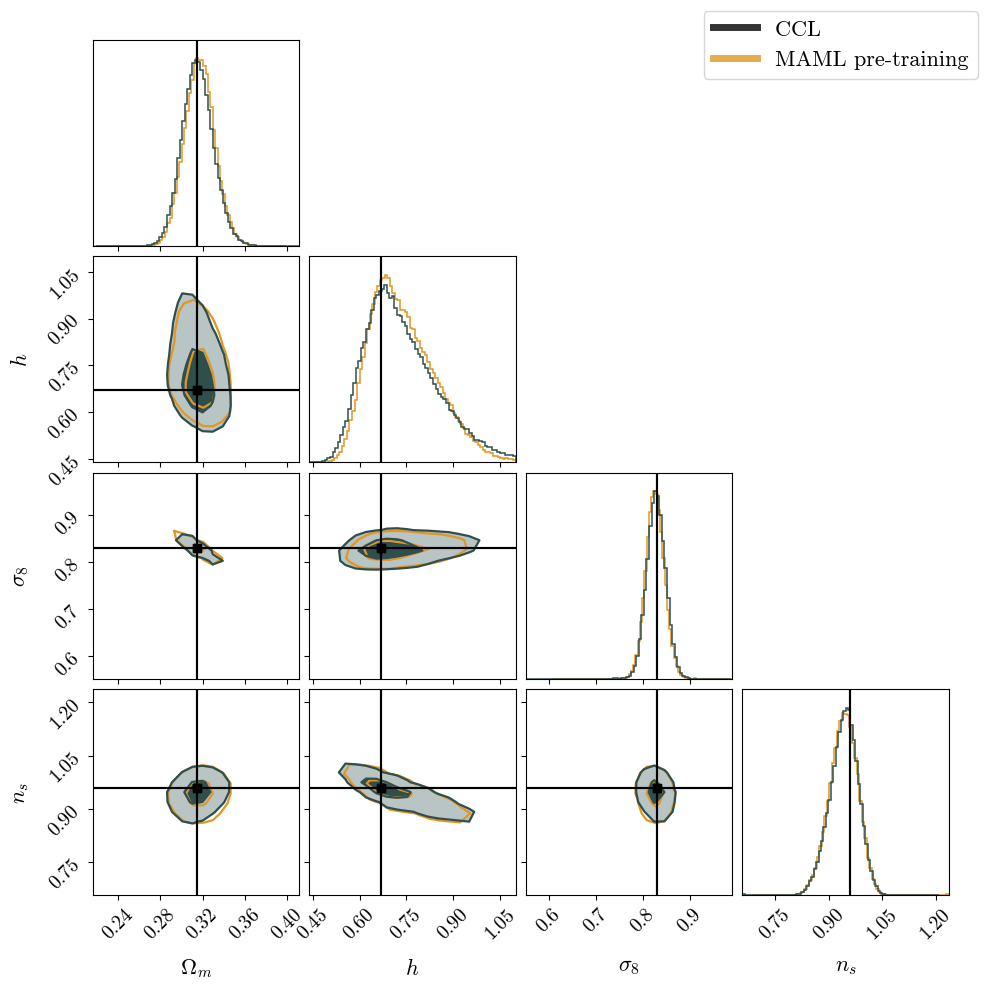

In [7]:

theta_fid = np.array([0.27+0.045, 0.67, 0.83, 0.96])
param_ranges = None #[(0.2, 0.5), (0.4, 1.1), (0.6, 1.0), (0.8, 1.1)]
smooth = 0
bins = 20
hist_factor = 4
levels = [0.393, 0.865]
lw = 1.1
clw = 1.6

colors_pop = ["#2F3B8F", "#349E91", "#E39620"]

labels = [r"$\Omega_m$", r"$h$", r"$\sigma_8$", r"$n_s$", r"$\delta^z_1$", r"$\delta^z_2$", ]

fig = plt.figure(figsize=(10, 10))

# Plot the corner plot
corner.corner(
    maml_samples, 
    labels=labels[:4], 
    truths=theta_fid,
    levels=levels,
    plot_datapoints=False,
    plot_density=False,
    color=colors_pop[2],
    truth_color='k',
    smooth=smooth,
    bins=bins,
    hist_bin_factor=hist_factor,
    range=param_ranges,
    hist_kwargs={'density': True, 'linewidth': lw},
    label_kwargs={'fontsize': 16},
    contour_kwargs={"linewidths": clw},
    fig=fig,
    no_fill_contours=True
)

# corner.corner(
#     pretrain_samples, 
#     labels=labels[:4], 
#     truths=theta_fid,
#     levels=levels,
#     plot_datapoints=False,
#     fill_contours=False,
#     plot_density=False,
#     color=colors_pop[0],
#     truth_color='k',
#     smooth=smooth,
#     bins=bins,
#     hist_bin_factor=hist_factor,
#     range=param_ranges,
#     hist_kwargs={'density': True, 'linewidth': lw},
#     label_kwargs={'fontsize': 16},
#     contour_kwargs={"linewidths": clw},
#     fig=fig
# )

# corner.corner(
#     fresh_samples, 
#     labels=labels[:4], 
#     truths=theta_fid,
#     levels=levels,
#     plot_datapoints=False,
#     fill_contours=False,
#     plot_density=False,
#     color=colors_pop[1],
#     truth_color='k',
#     smooth=smooth,
#     bins=bins,
#     hist_bin_factor=hist_factor,
#     range=param_ranges,
#     hist_kwargs={'density': True, 'linewidth': lw},
#     label_kwargs={'fontsize': 16},
#     contour_kwargs={"linewidths": clw},
#     fig=fig
# )

corner.corner(
    numerical_samples, 
    labels=labels[:4], 
    truths=theta_fid,
    levels=levels,
    plot_datapoints=False,
    fill_contours=True,
    plot_density=False,
    color='darkslategray',
    truth_color='k',
    smooth=smooth,
    bins=bins,
    hist_bin_factor=hist_factor,
    range=param_ranges,
    hist_kwargs={'density': True, 'linewidth': lw},
    label_kwargs={'fontsize': 16},
    contour_kwargs={"linewidths": clw},
    fig=fig
)

handles = [
    plt.Line2D([0], [0], color='k', lw=5, alpha=0.8, label='CCL '),
    plt.Line2D([0], [0], color=colors_pop[2], lw=5, alpha=0.8, label='MAML pre-training')
    # plt.Line2D([0], [0], color=colors_pop[0], lw=5, alpha=0.8, label='Pretrain'),
    # plt.Line2D([0], [0], color=colors_pop[1], lw=5, alpha=0.8, label='Fresh' )
]

for ax in fig.axes:
    ax.tick_params(axis='both', labelsize=14)

fig.legend(handles=handles, loc='upper right', fontsize=16)
plt.savefig('plots/mcmc_compare_emulators_IA.pdf', bbox_inches='tight', dpi=300)

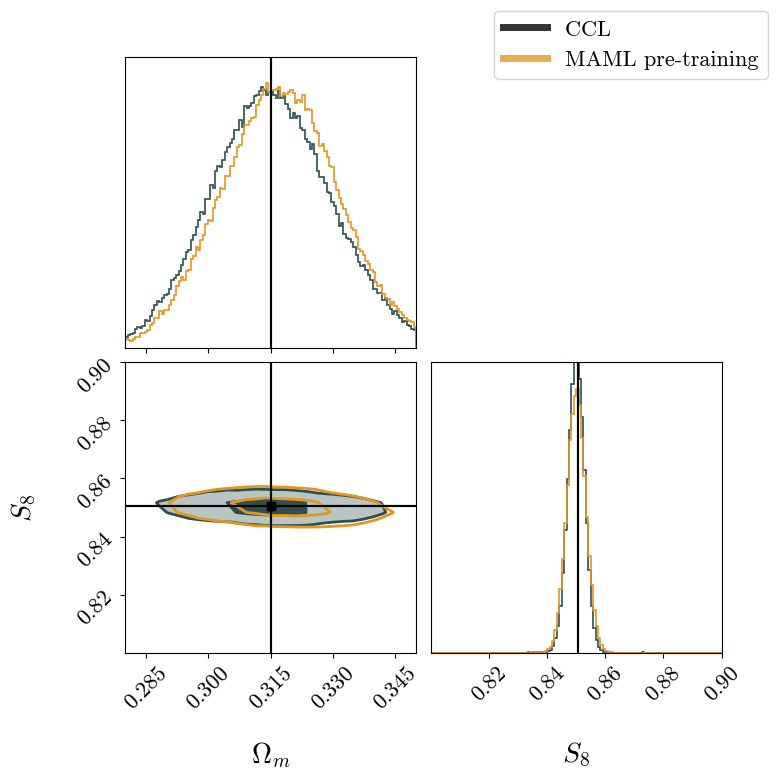

In [8]:
# Compute S8 values for each chain
def compute_S8(Omega_m, sigma8):
    return sigma8 * (Omega_m / 0.3)**0.5

S8_numerical = compute_S8(numerical_samples[:,0], numerical_samples[:,2])
S8_num_samples = np.vstack((numerical_samples[:,0], S8_numerical)).T

S8_maml = compute_S8(maml_samples[:,0], maml_samples[:,2])
S8_maml_samples = np.vstack((maml_samples[:,0], S8_maml)).T

S8_pretrain = compute_S8(pretrain_samples[:,0], pretrain_samples[:,2])
S8_pretrain_samples = np.vstack((pretrain_samples[:,0], S8_pretrain)).T

S8_fresh = compute_S8(fresh_samples[:,0], fresh_samples[:,2])
S8_fresh_samples = np.vstack((fresh_samples[:,0], S8_fresh)).T

truths = [theta_fid[0], compute_S8(theta_fid[0], theta_fid[2])]
levels = [0.393, 0.865]
smooth = 0
bins = 30
hist_factor = 4
param_ranges = [(0.28, 0.35), (0.8, 0.9)]
fill = False

fig = plt.figure(figsize=(8, 8))

colors=['#4059AD', '#97D8C4', '#F4B942']
colors_pop = ["#2F3B8F", "#349E91", "#E39620"]

lw = 1.2
clw = 2

# Plot the corner plot


# corner.corner(
#     S8_pretrain_samples, 
#     labels=[r"$\Omega_m$", r"$S_8$"], 
#     truths=truths,
#     levels=levels,
#     plot_datapoints=False,
#     fill_contours=False,
#     plot_density=False,
#     color=colors_pop[0],
#     truth_color='k',
#     smooth=smooth,
#     bins=bins,
#     hist_bin_factor=hist_factor,
#     range=param_ranges,
#     label_kwargs={'fontsize': 20},
#     hist_kwargs=dict(density=True, linewidth=lw),
#     contour_kwargs={"linewidths": clw},
#     fig=fig
# )

# corner.corner(
#     S8_fresh_samples, 
#     labels=[r"$\Omega_m$", r"$S_8$"], 
#     truths=truths,
#     levels=levels,
#     plot_datapoints=False,
#     fill_contours=False,
#     plot_density=False,
#     color=colors_pop[1],
#     truth_color='k',
#     smooth=smooth,
#     bins=bins,
#     hist_bin_factor=hist_factor,
#     range=param_ranges,
#     label_kwargs={'fontsize': 20},
#     hist_kwargs=dict(density=True, linewidth=lw),
#     contour_kwargs={"linewidths": clw},
#     fig=fig
# )

corner.corner(
    S8_num_samples, 
    labels=[r"$\Omega_m$", r"$S_8$"], 
    truths=truths,
    levels=levels,
    plot_datapoints=False,
    fill_contours=True,
    plot_density=False,
    color='darkslategray',
    truth_color='k',
    smooth=smooth,
    bins=bins,
    hist_bin_factor=hist_factor,
    range=param_ranges,
    label_kwargs={'fontsize': 20},
    hist_kwargs=dict(density=True, linewidth=lw),
    contour_kwargs={"linewidths": clw},
    fig=fig
)

corner.corner(
    S8_maml_samples, 
    labels=[r"$\Omega_m$", r"$S_8$"], 
    truths=truths,
    levels=levels,
    plot_datapoints=False,
    plot_density=False,
    color=colors_pop[2],
    truth_color='k',
    smooth=smooth,
    bins=bins,
    hist_bin_factor=hist_factor,
    range=param_ranges,
    label_kwargs={'fontsize': 20},
    hist_kwargs=dict(density=True, linewidth=lw),
    contour_kwargs={"linewidths": clw, 'linestyles':'-'},
    fig=fig,
    no_fill_contours=True
)

handles = [
    plt.Line2D([0], [0], color='k', lw=5, alpha=0.8, label='CCL '),
    plt.Line2D([0], [0], color=colors_pop[2], lw=5, alpha=0.8, label='MAML pre-training', ls='-'),
    # plt.Line2D([0], [0], color=colors_pop[0], lw=5, alpha=0.8, label='Pretrain'),
    # plt.Line2D([0], [0], color=colors_pop[1], lw=5, alpha=0.8, label='Fresh' )
]

for ax in fig.axes:
    ax.tick_params(axis='both', labelsize=16)

fig.legend(handles=handles, loc='upper right', fontsize=16)

plt.savefig('plots/S8_compare_emulators_IA.pdf', bbox_inches='tight', dpi=300)

Fine-tuning with a validation check instead of a set number of epochs appears to worsen the performance of the MAML model. Investigate further.
We observe increasing fine-tuning epochs up to 128 improves single task emulator but worsens MAML emulator.
Fine-tuning with 32 epochs has little effect on the performance of MAML but significantly worsens the performance of the pre-trained model

Seed 456, 363

In [9]:
def extract_summary_stats(samples, parameter_names=["Omega_m", "S8"]):
    """
    Compute median and 1σ uncertainties for parameters from posterior samples.
    
    Parameters:
    - samples: np.array of shape (N, 2), where each row is a sample [S8, Omega_m]
    - parameter_names: List of parameter names for reporting.
    
    Returns:
    - Dictionary with median and ±1σ uncertainties.
    """
    results = {}
    for i, param in enumerate(parameter_names):
        median = np.median(samples[:, i])
        lower = np.percentile(samples[:, i], 16)  # 16th percentile (1σ lower bound)
        upper = np.percentile(samples[:, i], 84)  # 84th percentile (1σ upper bound)
        err_lower = median - lower
        err_upper = upper - median
        results[param] = {"median": median, "1σ_lower": err_lower, "1σ_upper": err_upper}
    return results

# Extract statistics
summary_stats = {
    "CCL" : extract_summary_stats(S8_num_samples),
    "No pre-training" : extract_summary_stats(S8_fresh_samples),
    "Single-task pre-training" : extract_summary_stats(S8_pretrain_samples),
    "MAML pre-training" : extract_summary_stats(S8_maml_samples)
}

print('Fiducial values')
print(f'S8: {compute_S8(theta_fid[0], theta_fid[2]):.6f}')
print(f'Omega_m: {theta_fid[0]:.6f}')

# Print results in LaTeX format for a paper
for key, stats in summary_stats.items():
    print(key)
    for param, values in stats.items():
        print(f"{param}: {values['median']:.6f}^{{+{values['1σ_upper']:.6f}}}_{{-{values['1σ_lower']:.6f}}}")

Fiducial values
S8: 0.850497
Omega_m: 0.315000
CCL
Omega_m: 0.315140^{+0.014834}_{-0.014155}
S8: 0.850032^{+0.002833}_{-0.002908}
No pre-training
Omega_m: 0.349211^{+0.006148}_{-0.006520}
S8: 0.874960^{+0.004016}_{-0.003743}
Single-task pre-training
Omega_m: 0.311088^{+0.013996}_{-0.013997}
S8: 0.854972^{+0.003108}_{-0.003350}
MAML pre-training
Omega_m: 0.317374^{+0.014120}_{-0.014059}
S8: 0.850074^{+0.003259}_{-0.003290}


In [10]:
import numpy as np
import corner
from scipy.spatial import ConvexHull
from scipy.spatial.distance import euclidean
from scipy.linalg import det, inv

def get_contour_hull(samples, sigma_level):
    """Compute the convex hull enclosing the given credibility level of the posterior."""
    hist, x_edges, y_edges = np.histogram2d(samples[:, 0], samples[:, 1], bins=50)
    
    hist_flat = hist.ravel()
    sorted_indices = np.argsort(hist_flat)[::-1]
    cumsum = np.cumsum(hist_flat[sorted_indices]) / np.sum(hist_flat)

    threshold_index = np.argmax(cumsum >= sigma_level)
    threshold = hist_flat[sorted_indices][threshold_index]

    x_centers = 0.5 * (x_edges[:-1] + x_edges[1:])
    y_centers = 0.5 * (y_edges[:-1] + y_edges[1:])
    X, Y = np.meshgrid(x_centers, y_centers)
    mask = hist >= threshold

    points = np.vstack([X[mask], Y[mask]]).T
    return ConvexHull(points) if len(points) >= 3 else None

def bhattacharyya_distance(fid_samples, emul_samples):
    """Compute Bhattacharyya Distance between fiducial and emulator posteriors."""
    # Compute means
    mu_fid = np.mean(fid_samples, axis=0)
    mu_emul = np.mean(emul_samples, axis=0)

    # Compute covariance matrices
    cov_fid = np.cov(fid_samples, rowvar=False)
    cov_emul = np.cov(emul_samples, rowvar=False)

    # Compute average covariance
    cov_avg = 0.5 * (cov_fid + cov_emul)

    # Compute Mahalanobis distance (centroid shift)
    mean_diff = mu_fid - mu_emul
    mahalanobis_term = 0.125 * mean_diff.T @ inv(cov_avg) @ mean_diff

    # Compute determinant ratio term
    det_ratio = det(cov_avg) / np.sqrt(det(cov_fid) * det(cov_emul))
    log_term = 0.5 * np.log(det_ratio)

    return mahalanobis_term + log_term

def evaluate_emulator(fid_samples, emul_samples):
    """Compute coverage, centroid shift, and Bhattacharyya distance."""
    # hull_1sigma_fid = get_contour_hull(fid_samples, 0.393)
    # hull_2sigma_fid = get_contour_hull(fid_samples, 0.865)
    
    # hull_1sigma_emul = get_contour_hull(emul_samples, 0.393)
    # hull_2sigma_emul = get_contour_hull(emul_samples, 0.865)

    # coverage_1sigma = hull_1sigma_emul.volume / hull_1sigma_fid.volume if hull_1sigma_emul else None
    # coverage_2sigma = hull_2sigma_emul.volume / hull_2sigma_fid.volume if hull_2sigma_emul else None

    bhatta_dist = bhattacharyya_distance(fid_samples, emul_samples)

    return bhatta_dist

# Compute Bhattacharyya distance between CCL and emulator posteriors
bhatta_dist = evaluate_emulator(S8_num_samples, S8_fresh_samples)
print(f'Bhattacharyya distance (No pre-training): {bhatta_dist:.3f}')
bhatta_dist = evaluate_emulator(S8_num_samples, S8_pretrain_samples)
print(f'Bhattacharyya distance (Single-task pre-training): {bhatta_dist:.3f}')
bhatta_dist = evaluate_emulator(S8_num_samples, S8_maml_samples)
print(f'Bhattacharyya distance (MAML pre-training): {bhatta_dist:.3f}')


Bhattacharyya distance (No pre-training): 2.267
Bhattacharyya distance (Single-task pre-training): 0.074
Bhattacharyya distance (MAML pre-training): 0.007


In [11]:
# CPU based estimates in CPU core hours
data_gen = 11.2
maml_pt = 30
single_pt = 10

inference = 288

maml_total = data_gen + maml_pt + inference
single_total = data_gen + single_pt + inference
fresh_total = data_gen / 140 + inference

print(maml_total, single_total, fresh_total)

329.2 309.2 288.08


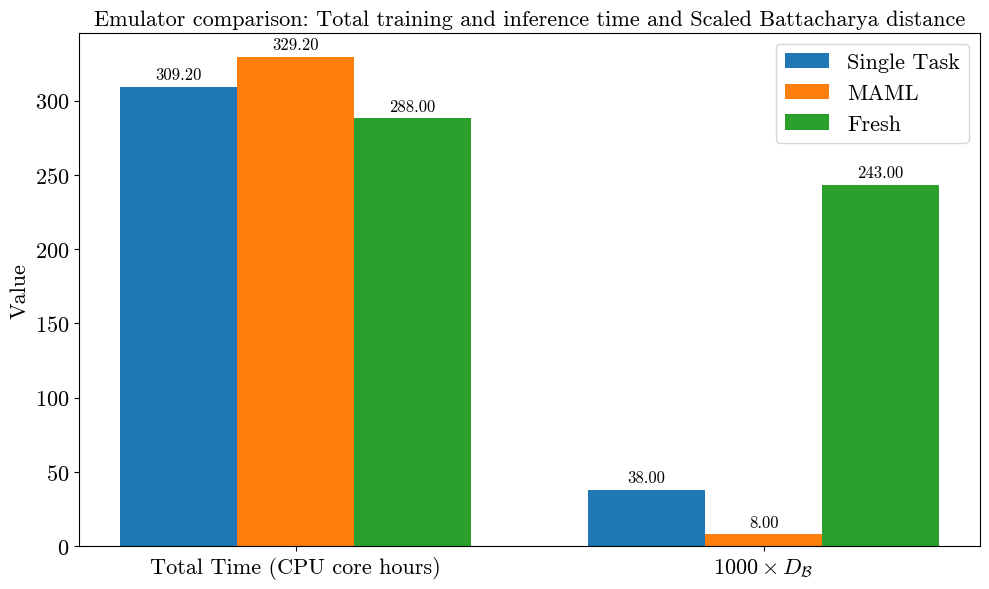

In [12]:
import matplotlib.pyplot as plt
import numpy as np

# Sample data
models = ['Single Task', 'MAML', 'Fresh']
total_time = [single_total, maml_total, inference]     # in seconds
error = np.array([0.038, 0.008, 0.243])*1000          # e.g. RMSE

# Grouped bar chart parameters
metrics = ['Total Time (CPU core hours)',r'$1000 \times D_{\mathcal{B}}$']
data = [total_time, error]

x = np.arange(len(metrics))  # the label locations
width = 0.25  # width of the bars

# Create figure and axes
fig, ax = plt.subplots(figsize=(10, 6))

# Plot each model's bars
for i in range(len(models)):
    ax.bar(x + i*width, [data[j][i] for j in range(len(metrics))], width, label=models[i])

# Add labels, title, and legend
ax.set_ylabel('Value', fontsize=16)
ax.set_title('Emulator comparison: Total training and inference time and Scaled Battacharya distance', fontsize=16)
ax.set_xticks(x + width)
ax.set_xticklabels(metrics)
ax.legend(fontsize=16)
ax.tick_params(labelsize=16)

# Optional: Add value labels above bars
for i in range(len(models)):
    for j in range(len(metrics)):
        value = data[j][i]
        ax.text(x[j] + i*width, value + 0.01 * max(total_time), f'{value:.2f}', ha='center', va='bottom', fontsize=12)

plt.tight_layout()
plt.show()